<a href="https://colab.research.google.com/github/ChelluriSritha/Password-Generator/blob/main/News_detectionipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn nltk joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (3).zip to archive (3).zip


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Fake.csv to Fake.csv


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving True.csv to True.csv


In [ ]:
import os

print(os.listdir())

['.config', 'Fake.csv', 'archive (3).zip', 'True.csv', 'sample_data']


In [ ]:
import pandas as pd

fake = pd.read_csv("Fake.csv")
true = pd.read_csv("True.csv")

print("Fake news:", fake.shape)
print("Real news:", true.shape)

Fake news: (23481, 4)
Real news: (21417, 4)


In [ ]:
fake['label'] = 0
true['label'] = 1

df = pd.concat([fake, true], ignore_index=True)

print("Combined dataset shape:", df.shape)

Combined dataset shape: (44898, 5)


In [ ]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

df.head()

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [ ]:
print(df.columns.tolist())

['title', 'text', 'subject', 'date', 'label']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB


In [ ]:
print(df.isnull().sum())

title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [ ]:
print(df['label'].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


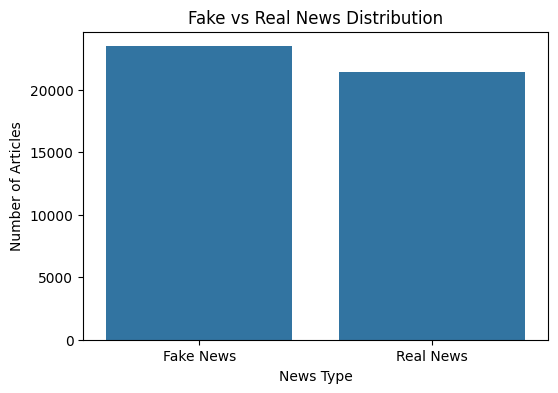

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))

sns.countplot(x='label', data=df)

plt.xticks([0, 1], ['Fake News', 'Real News'])
plt.xlabel('News Type')
plt.ylabel('Number of Articles')
plt.title('Fake vs Real News Distribution')

plt.show()

In [ ]:
df['content'] = df['title'].fillna('') + ' ' + df['text'].fillna('')

In [ ]:
df[['title', 'text', 'content', 'label']].head()

,title,text,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",Donald Trump heads for Scotland to reopen a go...,1


In [ ]:
import re
import string
import nltk

from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
def clean_text(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return ' '.join(words)

In [ ]:
df['clean_content'] = df['content'].apply(clean_text)

In [ ]:
df[['content', 'clean_content']].head()

,content,clean_content
0,Ben Stein Calls Out 9th Circuit Court: Committ...,ben stein calls th circuit court committed ‘co...
1,Trump drops Steve Bannon from National Securit...,trump drops steve bannon national security cou...
2,Puerto Rico expects U.S. to lift Jones Act shi...,puerto rico expects us lift jones act shipping...
3,OOPS: Trump Just Accidentally Confirmed He Le...,oops trump accidentally confirmed leaked israe...
4,Donald Trump heads for Scotland to reopen a go...,donald trump heads scotland reopen golf resort...


In [ ]:
X = df['clean_content']
y = df['label']

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (44898,)
y shape: (44898,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 35918
Testing samples: 8980


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_df=0.7,
    min_df=2,
    ngram_range=(1, 2)
)

In [ ]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [ ]:
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (35918, 1330127)
Testing TF-IDF shape: (8980, 1330127)


In [ ]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
lr_pred = lr_model.predict(X_test_tfidf)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print("Logistic Regression Results")
print("--------------------------------")
print("Accuracy :", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall   :", round(lr_recall * 100, 2), "%")
print("F1 Score :", round(lr_f1 * 100, 2), "%")

Logistic Regression Results
--------------------------------
Accuracy : 98.78 %
Precision: 98.22 %
Recall   : 99.23 %
F1 Score : 98.72 %


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    lr_pred,
    target_names=['FAKE', 'REAL']
))

              precision    recall  f1-score   support

        FAKE       0.99      0.98      0.99      4696
        REAL       0.98      0.99      0.99      4284

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



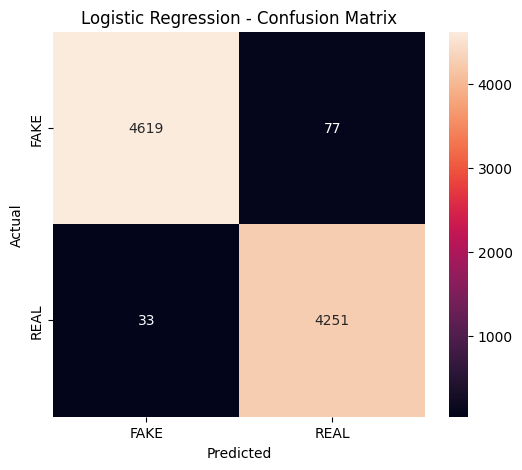

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['FAKE', 'REAL'],
    yticklabels=['FAKE', 'REAL']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')

plt.show()

In [ ]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [ ]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

print("Naive Bayes Results")
print("--------------------------------")
print("Accuracy :", round(nb_accuracy * 100, 2), "%")
print("Precision:", round(nb_precision * 100, 2), "%")
print("Recall   :", round(nb_recall * 100, 2), "%")
print("F1 Score :", round(nb_f1 * 100, 2), "%")

Naive Bayes Results
--------------------------------
Accuracy : 96.39 %
Precision: 95.06 %
Recall   : 97.5 %
F1 Score : 96.27 %


In [ ]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print("Linear SVM training completed!")

Linear SVM training completed!


In [ ]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("Linear SVM Results")
print("--------------------------------")
print("Accuracy :", round(svm_accuracy * 100, 2), "%")
print("Precision:", round(svm_precision * 100, 2), "%")
print("Recall   :", round(svm_recall * 100, 2), "%")
print("F1 Score :", round(svm_f1 * 100, 2), "%")

Linear SVM Results
--------------------------------
Accuracy : 99.64 %
Precision: 99.46 %
Recall   : 99.79 %
F1 Score : 99.63 %


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes',
        'Linear SVM'
    ],
    'Accuracy': [
        lr_accuracy,
        nb_accuracy,
        svm_accuracy
    ],
    'Precision': [
        lr_precision,
        nb_precision,
        svm_precision
    ],
    'Recall': [
        lr_recall,
        nb_recall,
        svm_recall
    ],
    'F1 Score': [
        lr_f1,
        nb_f1,
        svm_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.987751,0.982209,0.992297,0.987227
1,Naive Bayes,0.963920,0.950614,0.975023,0.962664
2,Linear SVM,0.996437,0.994649,0.997899,0.996271


In [ ]:
results_percentage = results.copy()

for column in ['Accuracy', 'Precision', 'Recall', 'F1 Score']:
    results_percentage[column] = (
        results_percentage[column] * 100
    ).round(2)

results_percentage

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,98.78,98.22,99.23,98.72
1,Naive Bayes,96.39,95.06,97.50,96.27
2,Linear SVM,99.64,99.46,99.79,99.63


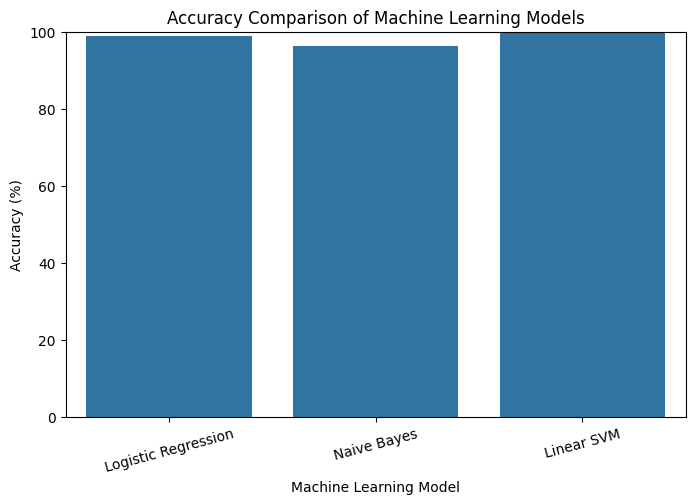

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=results_percentage,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy (%)')

plt.ylim(0, 100)

plt.xticks(rotation=15)

plt.show()

<Figure size 1000x600 with 0 Axes>

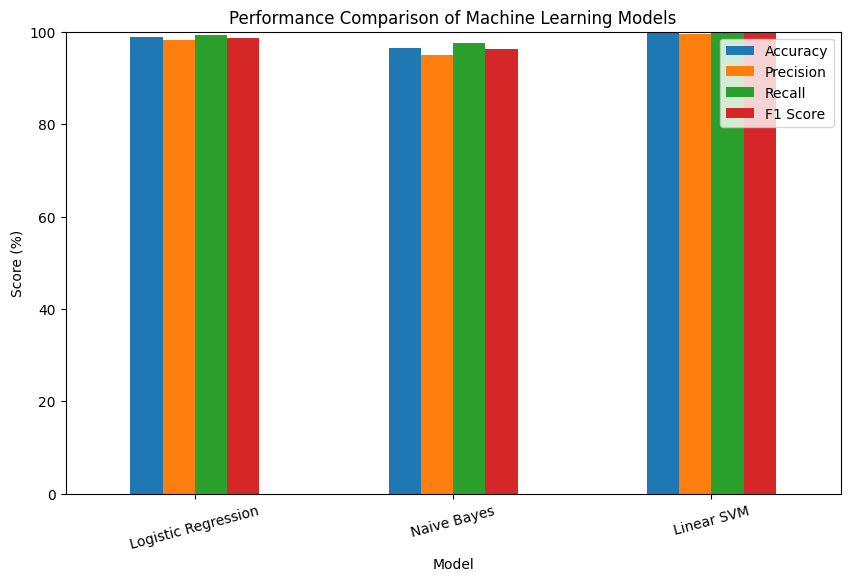

In [ ]:
plt.figure(figsize=(10,6))

results_plot = results_percentage.set_index('Model')

results_plot[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(10,6))

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Model')
plt.ylabel('Score (%)')

plt.ylim(0, 100)

plt.xticks(rotation=15)

plt.legend()

plt.show()

In [ ]:
best_model_name = results.loc[
    results['F1 Score'].idxmax(),
    'Model'
]

print("Best Model:", best_model_name)

Best Model: Linear SVM


In [ ]:
if best_model_name == 'Logistic Regression':
    best_model = lr_model
    final_pred = lr_pred

elif best_model_name == 'Naive Bayes':
    best_model = nb_model
    final_pred = nb_pred

else:
    best_model = svm_model
    final_pred = svm_pred

print("Selected model:", best_model_name)

Selected model: Linear SVM


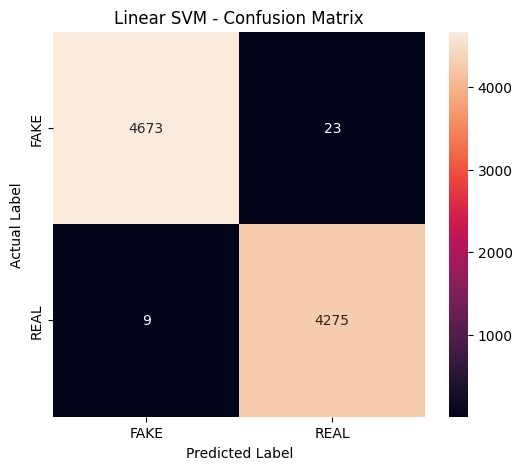

In [ ]:
cm = confusion_matrix(y_test, final_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['FAKE', 'REAL'],
    yticklabels=['FAKE', 'REAL']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title(f'{best_model_name} - Confusion Matrix')

plt.show()

In [ ]:
print("Final Model:", best_model_name)
print()

print(classification_report(
    y_test,
    final_pred,
    target_names=['FAKE', 'REAL']
))

Final Model: Linear SVM

              precision    recall  f1-score   support

        FAKE       1.00      1.00      1.00      4696
        REAL       0.99      1.00      1.00      4284

    accuracy                           1.00      8980
   macro avg       1.00      1.00      1.00      8980
weighted avg       1.00      1.00      1.00      8980



In [ ]:
final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred)
final_recall = recall_score(y_test, final_pred)
final_f1 = f1_score(y_test, final_pred)

print("FINAL MODEL PERFORMANCE")
print("========================")
print("Model     :", best_model_name)
print("Accuracy  :", round(final_accuracy * 100, 2), "%")
print("Precision :", round(final_precision * 100, 2), "%")
print("Recall    :", round(final_recall * 100, 2), "%")
print("F1 Score  :", round(final_f1 * 100, 2), "%")

FINAL MODEL PERFORMANCE
Model     : Linear SVM
Accuracy  : 99.64 %
Precision : 99.46 %
Recall    : 99.79 %
F1 Score  : 99.63 %


In [ ]:
import joblib

joblib.dump(best_model, 'fake_news_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


In [ ]:
from google.colab import files

files.download('fake_news_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download('tfidf_vectorizer.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
def predict_news(news_text):

    # Clean the input
    cleaned_text = clean_text(news_text)

    # Convert text into TF-IDF
    text_vector = tfidf.transform([cleaned_text])

    # Predict
    prediction = best_model.predict(text_vector)[0]

    if prediction == 0:
        return "FAKE NEWS"
    else:
        return "REAL NEWS"

In [ ]:
news = """
The government announced a new policy to improve
the quality of education across the country.
"""

result = predict_news(news)

print("Prediction:", result)

Prediction: FAKE NEWS


In [ ]:
news = """
Scientists have discovered a new technology that allows
humans to live without food or water for several months.
"""

result = predict_news(news)

print("Prediction:", result)

Prediction: FAKE NEWS


In [ ]:
while True:

    news = input("\nEnter news article (type 'exit' to stop): ")

    if news.lower() == 'exit':
        print("Program stopped.")
        break

    result = predict_news(news)

    print("Prediction:", result)


Enter news article (type 'exit' to stop): The government announced a new education policy that will improve higher education opportunities for students across the country.exit
Prediction: FAKE NEWS

Enter news article (type 'exit' to stop): The Reserve Bank of India announced that the monetary policy committee will keep the repo rate unchanged to support economic stability.exit
Prediction: FAKE NEWS

Enter news article (type 'exit' to stop): exit
Program stopped.


In [ ]:
results_percentage.to_csv(
    'model_comparison_results.csv',
    index=False
)

print("Results table saved!")

Results table saved!


In [ ]:
files.download('model_comparison_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install gradio

In [1]:
import gradio as gr

def predict_news_ui(news_text):
    if not news_text.strip():
        return "Please enter some news text."

    result = predict_news(news_text)
    return result

interface = gr.Interface(
    fn=predict_news_ui,
    inputs=gr.Textbox(
        lines=8,
        placeholder="Enter or paste a news article here..."
    ),
    outputs=gr.Textbox(label="Prediction"),
    title="Fake News Detection System",
    description="Enter a news article to predict whether it is REAL or FAKE."
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4d72209b660ed82289.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
